In [57]:
import numpy as np
import heapq
import time
import matplotlib.pyplot as plt
import pandas as pd
from astar import astar

grid = np.loadtxt("results/grid.csv", delimiter=",", dtype=int)
start = tuple(np.loadtxt("results/start.csv", delimiter=",", dtype=int))
goal = tuple(np.loadtxt("results/goal.csv", delimiter=",", dtype=int))

In [58]:
def manhattan_distance(current, goal):
    return abs(current[0] - goal[0]) + abs(current[1] - goal[1])

In [59]:
def visualize_all_paths(grid, starts, goals, results, title="Multi-Robot A*"):

    rows, cols = grid.shape
    n = len(starts)

    fig, ax = plt.subplots(figsize=(10, 8))

    # Display obstacles
    ax.imshow(grid, cmap="Greys", vmin=0, vmax=1)

    # Unique color for each robot
    colors = plt.cm.tab10(np.linspace(0, 1, n))

    for i in range(n):

        color = colors[i]
        result = results[f"Robot {i+1}"]

        if not result["success"]:
            print(f"Robot {i+1}: No path found")
            continue

        path = result["path"]

        # Extract row and column coordinates
        path_rows = [pos[0] for pos in path]
        path_cols = [pos[1] for pos in path]

        # Draw path
        ax.plot(
            path_cols,
            path_rows,
            color=color,
            linewidth=2.5,
            marker=".",
            markersize=6,
            label=f"Robot {i+1} Path",
            zorder=2
        )

        # Starting position
        ax.scatter(
            starts[i][1],
            starts[i][0],
            color=color,
            s=250,
            marker="o",
            edgecolors="black",
            linewidths=1.5,
            label=f"Robot {i+1} Start",
            zorder=3
        )

        # Goal position
        ax.scatter(
            goals[i][1],
            goals[i][0],
            color=color,
            s=300,
            marker="*",
            edgecolors="black",
            linewidths=1,
            label=f"Robot {i+1} Goal",
            zorder=3
        )

    # Grid formatting
    ax.set_xticks(np.arange(-0.5, cols, 1))
    ax.set_yticks(np.arange(-0.5, rows, 1))

    ax.grid(color="gray", linewidth=0.5)

    ax.set_xticklabels([])
    ax.set_yticklabels([])

    ax.set_xlim(-0.5, cols - 0.5)
    ax.set_ylim(rows - 0.5, -0.5)

    ax.set_title(title, fontsize=15)

    # Place legend outside the grid
    ax.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=9
    )

    plt.tight_layout()
    plt.show()

In [60]:
import importlib
import astar

importlib.reload(astar)

from astar import astar

Results for Robot 1:
------------------------------
Success: True
Path length: 9
Nodes expanded: 26
Maximum frontier size: 16
Results for Robot 2:
------------------------------
Success: True
Path length: 1
Nodes expanded: 1
Maximum frontier size: 4
Results for Robot 3:
------------------------------
Success: True
Path length: 8
Nodes expanded: 13
Maximum frontier size: 13
Results for Robot 4:
------------------------------
Success: True
Path length: 8
Nodes expanded: 8
Maximum frontier size: 17
Results for Robot 5:
------------------------------
Success: True
Path length: 9
Nodes expanded: 27
Maximum frontier size: 19
Results for Robot 6:
------------------------------
Success: True
Path length: 9
Nodes expanded: 26
Maximum frontier size: 19
Results for Robot 7:
------------------------------
Success: True
Path length: 6
Nodes expanded: 11
Maximum frontier size: 15
Results for Robot 8:
------------------------------
Success: True
Path length: 11
Nodes expanded: 27
Maximum frontier siz

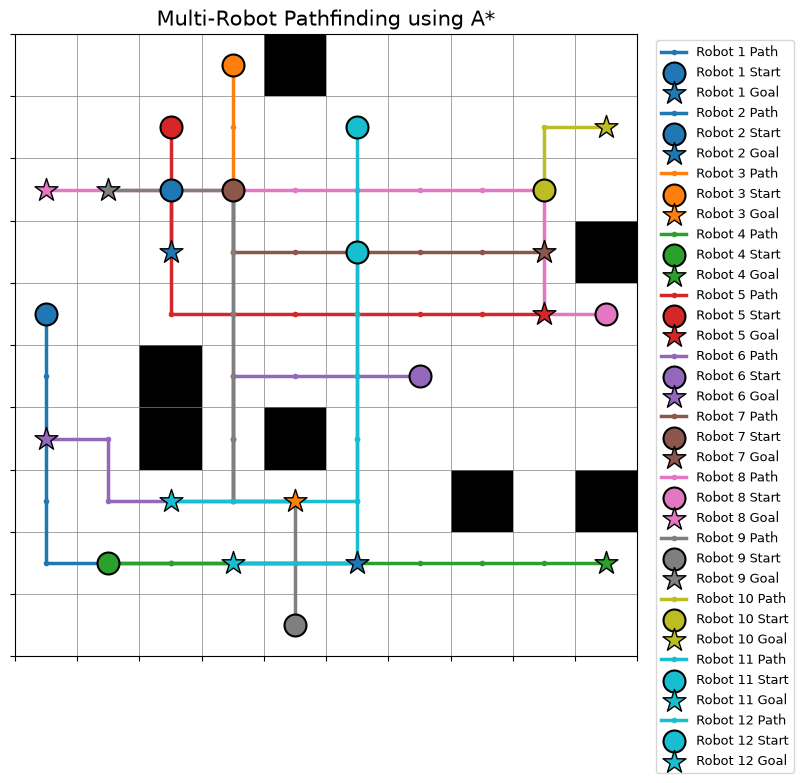

In [61]:
no_of_robots = len(start) 
results = {}

for i in range(no_of_robots):

    result = astar(grid, start[i], goal[i], manhattan_distance)

    results[f"Robot {i+1}"] = result

    print(f"Results for Robot {i+1}:")
    print("-" * 30)
    print("Success:", result["success"])
    print("Path length:", result["path_length"])
    print("Nodes expanded:", result["nodes_expanded"])
    print("Maximum frontier size:", result["max_frontier_size"])
    
visualize_all_paths(
    grid,
    start,
    goal,
    results,
    title="Multi-Robot Pathfinding using A*"
)
